# 06 — CTGAN em um cenário logístico simulado

**EntregaCerta AI | Laboratório separado da aplicação.**

Pergunta: acrescentar 30 mil exemplos gerados por CTGAN ajuda a aprender uma regra
logística definida pela equipe? Avaliaremos os mesmos pedidos reservados com e sem
injeção. Também mostraremos, em outro experimento, o atraso **observado** na Olist.

> Transportadoras, sua reputação e `atrasou_simulado` são hipóteses. Um F1 alto
> nesse alvo não prova melhoria nos atrasos reais. Não substituímos o modelo web.

Use o kernel **.venv-ctgan**. Execute as células na ordem. O guia completo está em
`Docs/guia_simulacao_ctgan.md`; o código executável está em `src/simulacao_logistica/`.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import subprocess
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/simulacao_logistica").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from src.simulacao_logistica.dados import ATRIBUTOS, PROIBIDAS
from src.simulacao_logistica.avaliacao import metricas as calcular_metricas
print("Projeto:", RAIZ.name)

Projeto: EntregaCertaAI


## 1. Reproduzir ou consultar a execução pronta

Para gerar tudo do início, altere `EXECUTAR_PIPELINE` para `True`. O comando consulta
o PostgreSQL e os CSVs originais; reutiliza o gerador se as entradas forem idênticas.
Em CPU, treinar a GAN pela primeira vez pode levar bastante tempo. Sem execução
prévia, o notebook interrompe com uma mensagem clara.

Configurações: `cenario_logistico.json` define as hipóteses;
`geracao_ctgan.json` define quantidades e treinamento. Sementes controlam o sorteio,
não a intensidade do risco. O cenário inicial usa 30.000/0/0 sintéticos.

In [2]:
EXECUTAR_PIPELINE = False
if EXECUTAR_PIPELINE:
    subprocess.run([sys.executable, "-m", "src.simulacao_logistica", "--etapa", "tudo"],
                   cwd=RAIZ, check=True)

indicador = RAIZ / "Modelos/experimento_simulacao/ultima_execucao.txt"
if not indicador.exists():
    raise FileNotFoundError("Execute o pipeline ou defina EXECUTAR_PIPELINE = True.")
execucao = indicador.read_text(encoding="utf-8").strip()
PASTA = indicador.parent / execucao
if not (PASTA / "metricas.csv").exists():
    raise FileNotFoundError("Preparação encontrada, mas avaliação não concluída. Execute --etapa tudo.")
manifesto = json.loads((PASTA / "manifesto.json").read_text(encoding="utf-8"))
preparacao = joblib.load(PASTA / "preparacao.joblib")
base = preparacao["base"]
sinteticos = joblib.load(PASTA / "sinteticos.joblib")
resultados = pd.read_csv(PASTA / "metricas.csv")
previsoes = pd.read_csv(PASTA / "previsoes.csv")
eleitos = pd.read_csv(PASTA / "selecionados_na_validacao.csv")
CSV = RAIZ / "Dados/simulacao_ctgan" / execucao / "pedidos_cenario_e_injetados.csv"
print("Execução:", execucao)
print("CSV:", CSV.relative_to(RAIZ))
display(pd.Series(manifesto["versoes"], name="Versão utilizada").to_frame())

Execução: 7ca2a1faf2c49a6b
CSV: Dados\simulacao_ctgan\7ca2a1faf2c49a6b\pedidos_cenario_e_injetados.csv


,Versão utilizada
numpy,2.5.4
pandas,2.3.3
scikit-learn,1.9.1
torch,2.15.0+cpu
ctgan,0.13.0
rdt,2.1.0


## 2. Primeira leitura: o que foi medido?

Os modelos e limiares abaixo foram escolhidos pelo F1 na validação, com AP no
desempate. O teste apenas mede o resultado da escolha. Compare o ganho da CTGAN
dentro do mesmo alvo; o atraso observado é outro problema. O teste Olist já foi
consultado em experimentos anteriores, portanto esta comparação é retrospectiva.

In [3]:
resumo = resultados.merge(eleitos[["experimento", "modelo"]],
                          on=["experimento", "modelo"], validate="many_to_one")
resumo = resumo.loc[resumo.particao.eq("teste") & resumo.populacao.eq("atributos_olist")]
colunas_resumo = ["experimento", "modelo", "pedidos", "atrasos", "precision", "recall", "f1", "AP", "accuracy", "brier"]
display(resumo[colunas_resumo].round(4).reset_index(drop=True))
print("As linhas 'simulado' avaliam regras fictícias. A linha 'observado' avalia os atrasos Olist.")

,experimento,modelo,pedidos,atrasos,precision,recall,f1,AP,accuracy,brier
0,observado_sem_injecao,Logistica,25120,1123,0.0719,0.7667,0.1315,0.0966,0.5472,0.0422
1,simulado_sem_ctgan,HGB,25120,3239,0.8042,0.7089,0.7535,0.8554,0.9402,0.0434
2,simulado_com_ctgan,HGB,25120,3239,0.8030,0.7691,0.7857,0.8795,0.9459,0.0392


As linhas 'simulado' avaliam regras fictícias. A linha 'observado' avalia os atrasos Olist.


## 3. Conferir a origem, os rótulos e a divisão

Mantemos apenas pedidos com um vendedor. Os atributos vêm da Olist e os pedidos
sintéticos ficam identificados. Os rótulos observados não são preenchidos nos
sintéticos. As datas são metadados; não entram como datas de entrega no modelo.

A meta de aproximadamente 1/6 de atrasos simulados vale para o treino. Validação e
teste mantêm o intercepto e podem apresentar frequências diferentes.

In [4]:
assert base.order_id.is_unique
assert base.origem_dado.eq("atributos_olist").all()
assert not PROIBIDAS.intersection(ATRIBUTOS)
for coluna in ["ultima_avaliacao_vendedor", "ultima_avaliacao_transportadora"]:
    assert (base[coluna].isna() | base[coluna].lt(base.order_approved_at)).all()
if not sinteticos.empty:
    assert sinteticos.order_id.is_unique
    assert not set(sinteticos.order_id).intersection(base.order_id)
    assert sinteticos.origem_dado.eq("sintetico_ctgan").all()
    assert sinteticos.atrasou_observado.isna().all()
    for parte in ["treino", "validacao", "teste"]:
        assert int(sinteticos.particao.eq(parte).sum()) == manifesto["config_geracao"][parte]

coortes = pd.read_csv(PASTA / "coortes.csv")
coortes["taxa_observada"] = coortes.atrasos_observados / coortes.pedidos
coortes["taxa_simulada"] = coortes.atrasos_simulados / coortes.pedidos
display(coortes.round(4))
if not sinteticos.empty:
    display(sinteticos.groupby("particao").agg(pedidos=("order_id", "size"),
        atrasos_simulados=("atrasou_simulado", "sum")))
print("Conferências de identidade, origem, quantidades e históricos: aprovadas.")
if not sinteticos.empty:
    treino_aumentado = pd.concat([base.loc[base.particao.eq("treino")], sinteticos.loc[sinteticos.particao.eq("treino")]], ignore_index=True)
    print(f"Atrasos simulados no treino aumentado: {treino_aumentado.atrasou_simulado.mean():.2%}")

,particao,pedidos,atrasos_observados,atrasos_simulados,probabilidade_media_regra,taxa_observada,taxa_simulada
0,teste,25120,1123,3239,0.1298,0.0447,0.1289
1,treino,40710,1761,6786,0.1669,0.0433,0.1667
2,validacao,24337,2489,3107,0.1284,0.1023,0.1277


,pedidos,atrasos_simulados
particao,,
treino,30000,8222


Conferências de identidade, origem, quantidades e históricos: aprovadas.


Atrasos simulados no treino aumentado: 21.22%


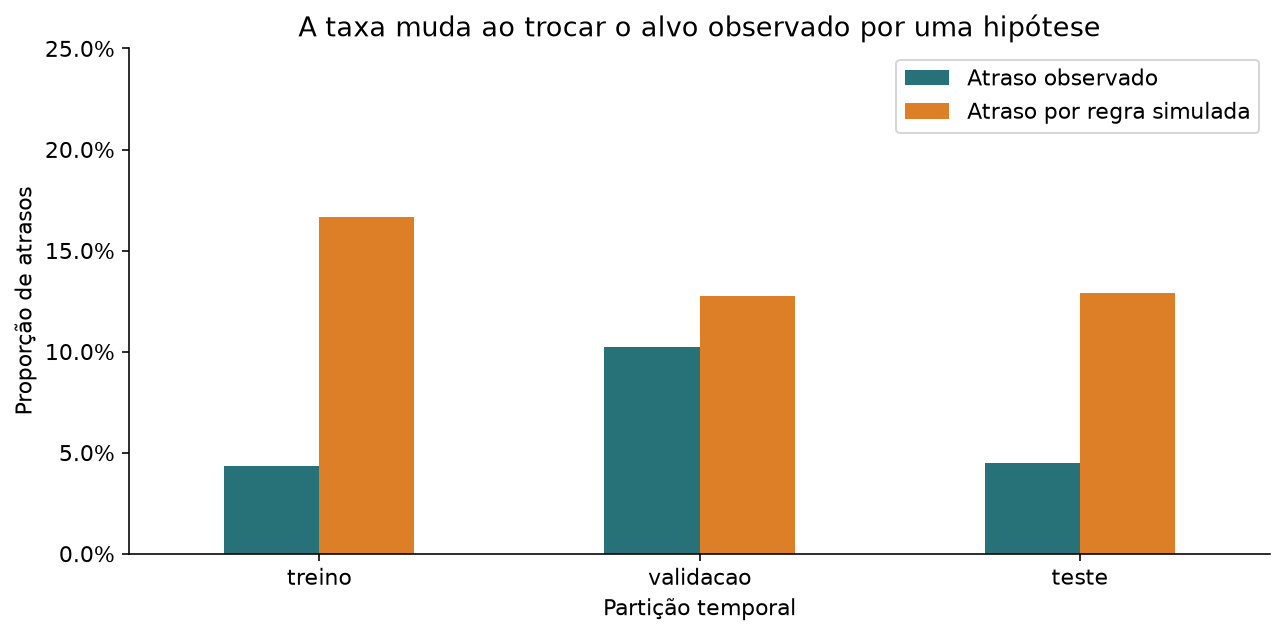

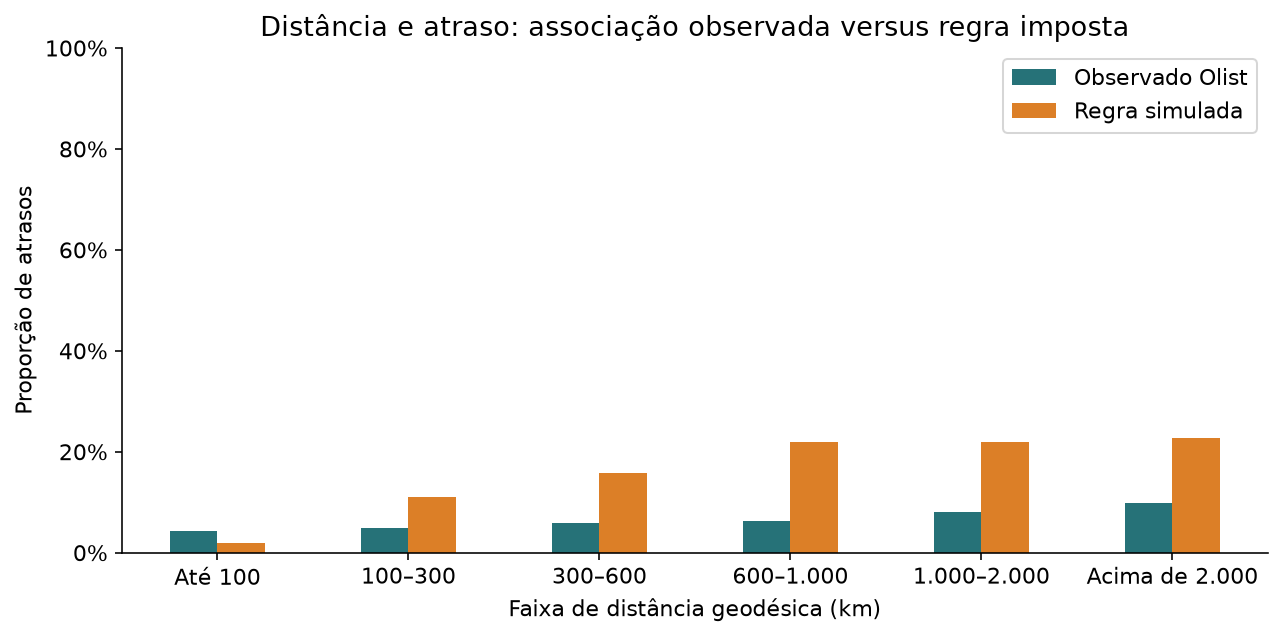

In [5]:
display(Image(filename=str(PASTA / "01_classes.png")))
display(Image(filename=str(PASTA / "02_distancia.png")))

**Leitura:** o gráfico de distância compara uma associação histórica a uma regra
que impusemos. Não demonstra causalidade. As figuras incluem os pedidos Olist das
três partições; não os gerados. Distâncias e coordenadas são aproximações por CEP.

## 4. Inspecionar as regras e os registros

Frete relativo e transformações da regra são ajustados só no treino. O histórico
do vendedor usa avaliações anteriores; o da transportadora é simulado. A CTGAN
gera atributos das duas classes e as regras congeladas atribuem o novo alvo depois.
`probabilidade_regra` é uma coluna de auditoria, **nunca uma entrada do classificador**.

In [6]:
config = manifesto["config_cenario"]
display(pd.Series(config["influencias"], name="Coeficiente hipotético").to_frame())
display(pd.DataFrame.from_dict(config["transportadoras"], orient="index"))
print("Geração:", manifesto["config_geracao"])
print("Intensidade:", config["intensidade_sinal"], "| Ruído:", config["ruido_logit"])
campos = ["order_id", "origem_dado", "particao", "customer_state", "transportadora",
          "distancia_vendedor_cliente_km", "peso_total_g", "atrasou_observado", "atrasou_simulado"]
display(pd.concat([base[campos].head(3), sinteticos.reindex(columns=campos).head(3)], ignore_index=True))

,Coeficiente hipotético
distancia_vendedor_cliente_km,1.20
peso_total_g,0.60
volume_total_cm3,0.50
altura_max_item_cm,0.30
valor_itens,0.20
frete_relativo,-0.90
nota_historica_vendedor,-0.30
nota_historica_transportadora,-0.50
prazo_prometido_dias,-0.60
quantidade_itens,0.10


,efeito,distancia,nota_media
SIM_A,-0.5,0.1,4.5
SIM_B,0.0,0.3,3.6
SIM_C,0.7,0.7,2.8


Geração: {'treino': 30000, 'validacao': 0, 'teste': 0, 'epocas': 100, 'seed_ctgan': 42, 'batch_size': 500, 'limite_por_particao': 30000}
Intensidade: 2.5 | Ruído: 0.25


,order_id,origem_dado,particao,customer_state,transportadora,distancia_vendedor_cliente_km,peso_total_g,atrasou_observado,atrasou_simulado
0,bfbd0f9bdef84302105ad712db648a6c,atributos_olist,treino,SP,SIM_B,566.040993,3000.000000,1,1
1,1ff217aa612f6cd7c4255c9bfe931c8b,atributos_olist,treino,SP,SIM_C,306.906173,200.000000,0,0
2,cd3b8574c82b42fc8129f6d502690c3e,atributos_olist,treino,SP,SIM_C,194.572193,9000.000000,0,0
3,SIM-treino-1042-000000,sintetico_ctgan,treino,MG,SIM_B,474.356392,1167.624022,<NA>,1
4,SIM-treino-1042-000001,sintetico_ctgan,treino,MG,SIM_A,491.656516,1495.322749,<NA>,0
5,SIM-treino-1042-000002,sintetico_ctgan,treino,DF,SIM_B,434.490602,NaN,<NA>,0


## 5. A qualidade dos sintéticos é suficiente?

KS e TVD variam de 0 a 1: menor significa maior semelhança **marginal**. Elas não
comprovam que todas as relações são realistas. A ausência de duplicatas exatas
também não garante privacidade. Peso, frete e distância estão em escala logarítmica.

A meta de 1/6 é ajustada na base Olist de treino antes da injeção. A distribuição
dos sintéticos pode alterar sua taxa de atrasos e a do treino aumentado. Por isso,
o ganho do braço aumentado inclui essa mudança de classes, não apenas mais amostras.

,coluna,tipo,distancia_ks,media_olist,media_ctgan,fracao_nulos_olist,fracao_nulos_ctgan,distancia_tvd
21,prazo_prometido_dias,numerica,0.2187,24.6703,21.8874,0.0000,0.0000,NaN
29,nota_historica_vendedor,numerica,0.2102,3.9751,4.0844,0.0000,0.0000,NaN
17,frete_relativo,numerica,0.1909,0.0000,0.0041,0.0000,0.0000,NaN
31,nota_historica_transportadora,numerica,0.1802,3.5718,3.5520,0.0000,0.0000,NaN
15,frete_sobre_valor_itens,numerica,0.1777,0.3047,0.6343,0.0000,0.0000,NaN
22,tempo_aprovacao_horas,numerica,0.1763,9.9001,14.3152,0.0000,0.0000,NaN
10,peso_max_item_g,numerica,0.1625,2208.0469,1238.7373,0.0004,0.0529,NaN
6,valor_itens,numerica,0.1434,136.5370,97.5180,0.0000,0.0000,NaN
13,preco_medio_item,numerica,0.1427,125.6934,93.5007,0.0000,0.0000,NaN
0,distancia_vendedor_cliente_km,numerica,0.1412,611.4210,851.4830,0.0051,0.0563,NaN


,coluna,distancia_tvd
33,customer_state,0.0939
34,categoria_principal,0.1099
35,tipo_pagamento_principal,0.0285
36,transportadora,0.0406


Linhas identicas entre sinteticos: 0
Linhas identicas ao treino: 0
Nao equivale a uma auditoria de privacidade.


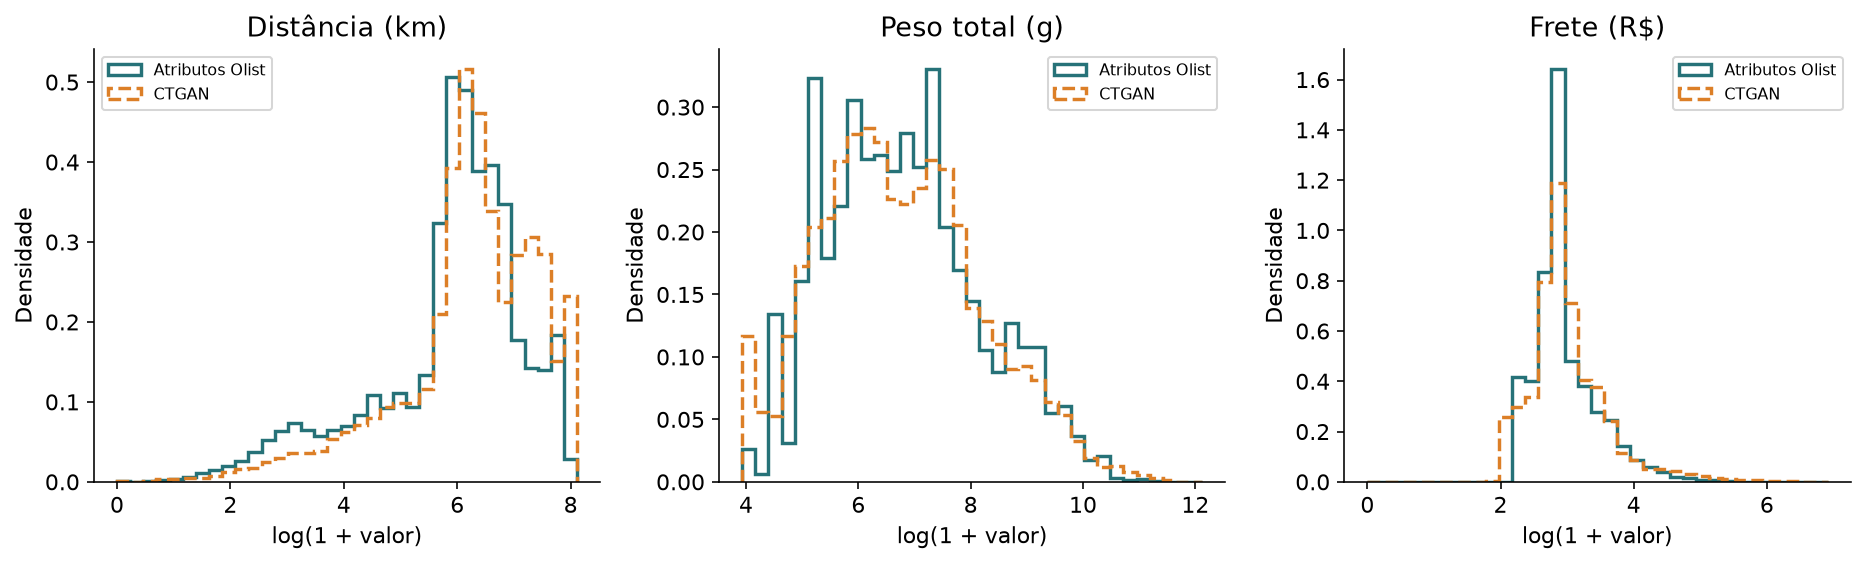

In [7]:
if (PASTA / "qualidade_sinteticos.csv").exists():
    qualidade = pd.read_csv(PASTA / "qualidade_sinteticos.csv")
    display(qualidade.loc[qualidade.tipo.eq("numerica")].sort_values("distancia_ks", ascending=False).head(10).round(4))
    display(qualidade.loc[qualidade.tipo.eq("categorica"), ["coluna", "distancia_tvd"]].round(4))
    print((PASTA / "duplicatas_sinteticas.txt").read_text(encoding="utf-8"))
    display(Image(filename=str(PASTA / "07_distribuicoes.png")))
else:
    print("Não há sintéticos no treino nesta configuração.")

## 6. Comparação de desempenho

Dummy fornece a referência simples. Regressão logística e HGB recebem o mesmo
pré-processamento ajustado no treino Olist. O braço aumentado soma 30 mil sintéticos
aos pedidos de treino, mantendo validação e teste iguais ao braço sem CTGAN.
Precisão, recall, F1 e AP não são intercambiáveis. A fila de 10% é uma segunda
política de seleção e não utiliza o mesmo limiar escolhido para maximizar F1.

,experimento,modelo,particao,treino_pedidos,f1,precision,recall,AP,accuracy,atrasos_top10,precision_top10,recall_top10
0,observado_sem_injecao,Dummy,validacao,40710,0.0000,0.0000,0.0000,0.1023,0.8977,86,0.0353,0.0346
1,observado_sem_injecao,Dummy,teste,40710,0.0000,0.0000,0.0000,0.0447,0.9553,112,0.0446,0.0997
2,observado_sem_injecao,Logistica,validacao,40710,0.2618,0.1804,0.4769,0.1975,0.7250,597,0.2454,0.2399
3,observado_sem_injecao,Logistica,teste,40710,0.1315,0.0719,0.7667,0.0966,0.5472,284,0.1131,0.2529
4,observado_sem_injecao,HGB,validacao,40710,0.2189,0.1349,0.5793,0.1490,0.5771,425,0.1747,0.1708
5,observado_sem_injecao,HGB,teste,40710,0.1404,0.0780,0.6981,0.0906,0.6178,277,0.1103,0.2467
6,simulado_sem_ctgan,Dummy,validacao,40710,0.0000,0.0000,0.0000,0.1277,0.8723,323,0.1328,0.1040
7,simulado_sem_ctgan,Dummy,teste,40710,0.0000,0.0000,0.0000,0.1289,0.8711,498,0.1982,0.1538
8,simulado_sem_ctgan,Logistica,validacao,40710,0.7341,0.6874,0.7876,0.8064,0.9271,1930,0.7933,0.6212
9,simulado_sem_ctgan,Logistica,teste,40710,0.7136,0.7531,0.6780,0.8017,0.9298,2013,0.8014,0.6215


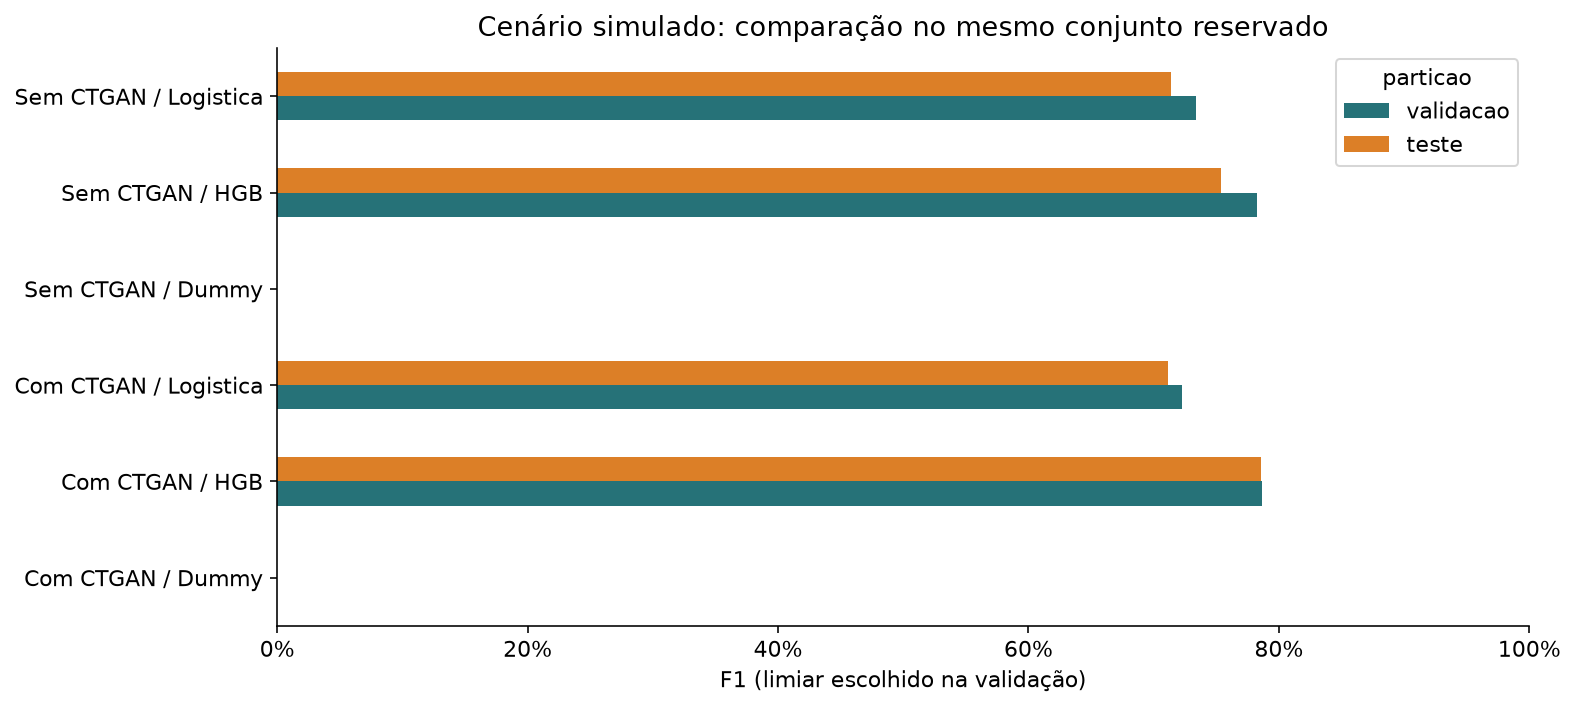

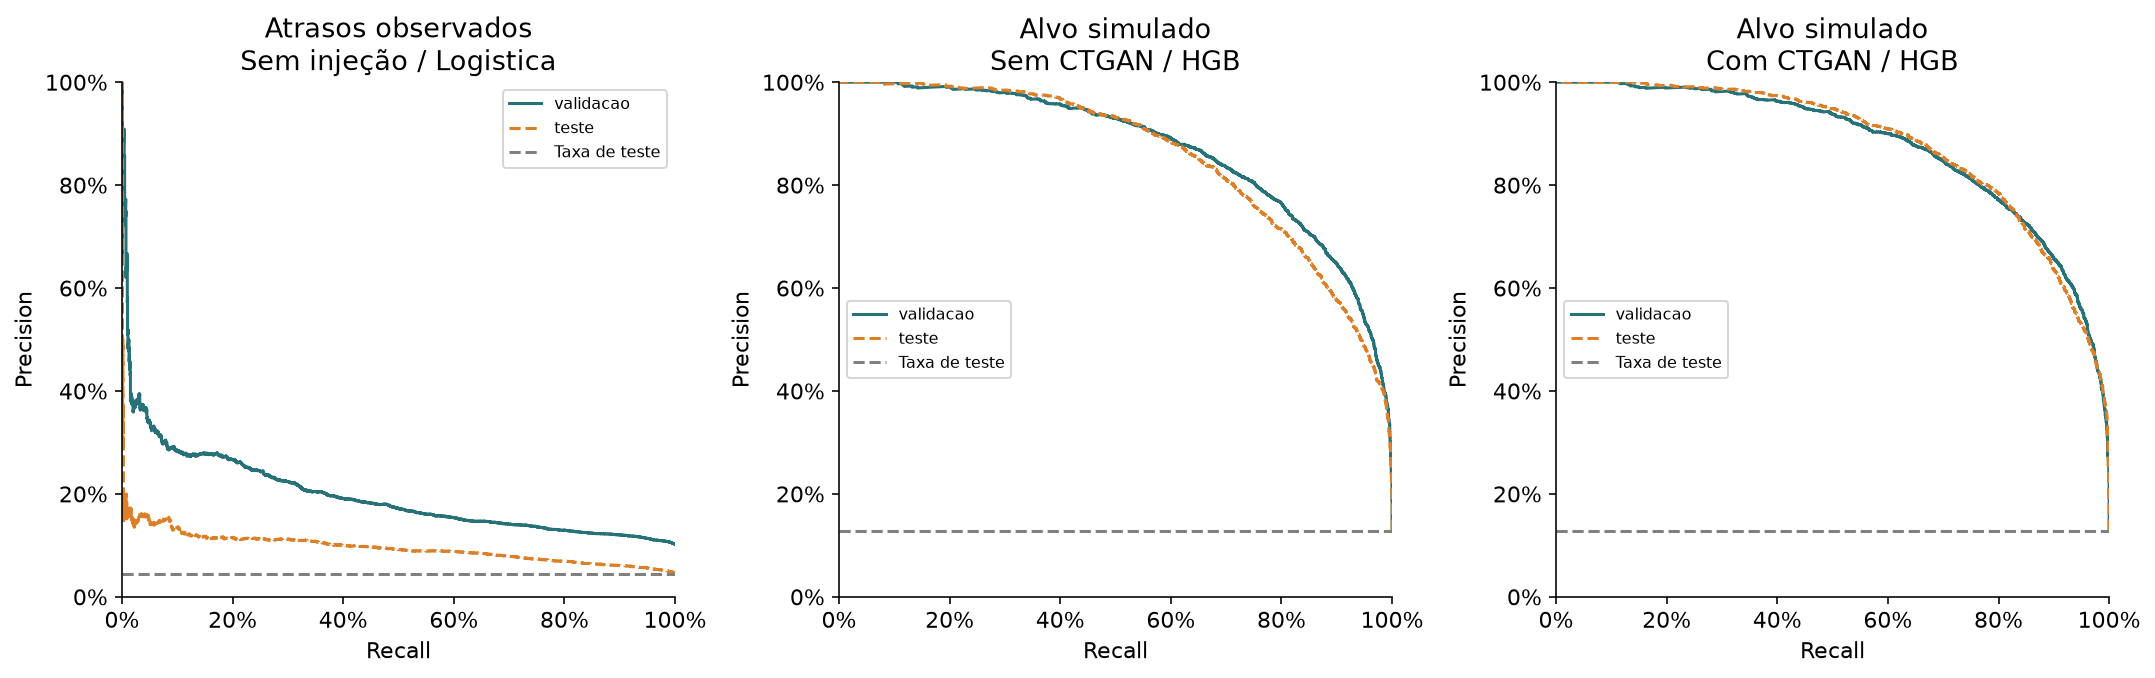

In [8]:
colunas = ["experimento", "modelo", "particao", "treino_pedidos", "f1", "precision", "recall", "AP", "accuracy", "atrasos_top10", "precision_top10", "recall_top10"]
display(resultados.loc[resultados.populacao.eq("atributos_olist"), colunas].round(4))
display(Image(filename=str(PASTA / "03_f1_cenario.png")))
display(Image(filename=str(PASTA / "04_precision_recall.png")))

## 7. Erros e calibração

As matrizes mostram o teste dos modelos escolhidos na validação. Quanto mais
próxima da diagonal a curva de calibração, melhor o alinhamento do score à frequência
do **respectivo alvo**. Uma probabilidade calibrada de atraso simulado ainda não é
uma probabilidade de atraso real.

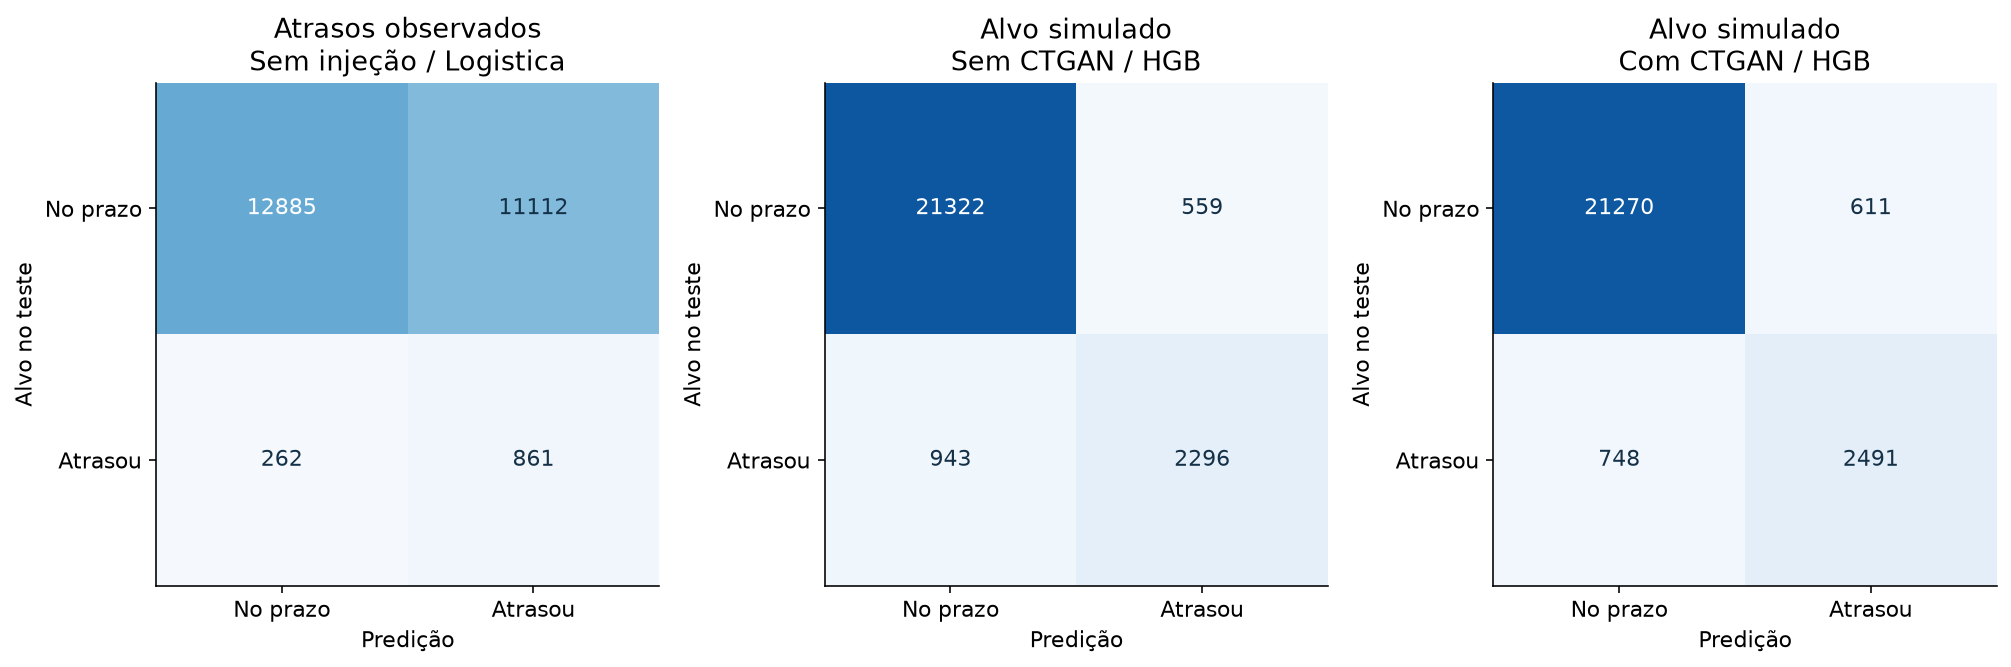

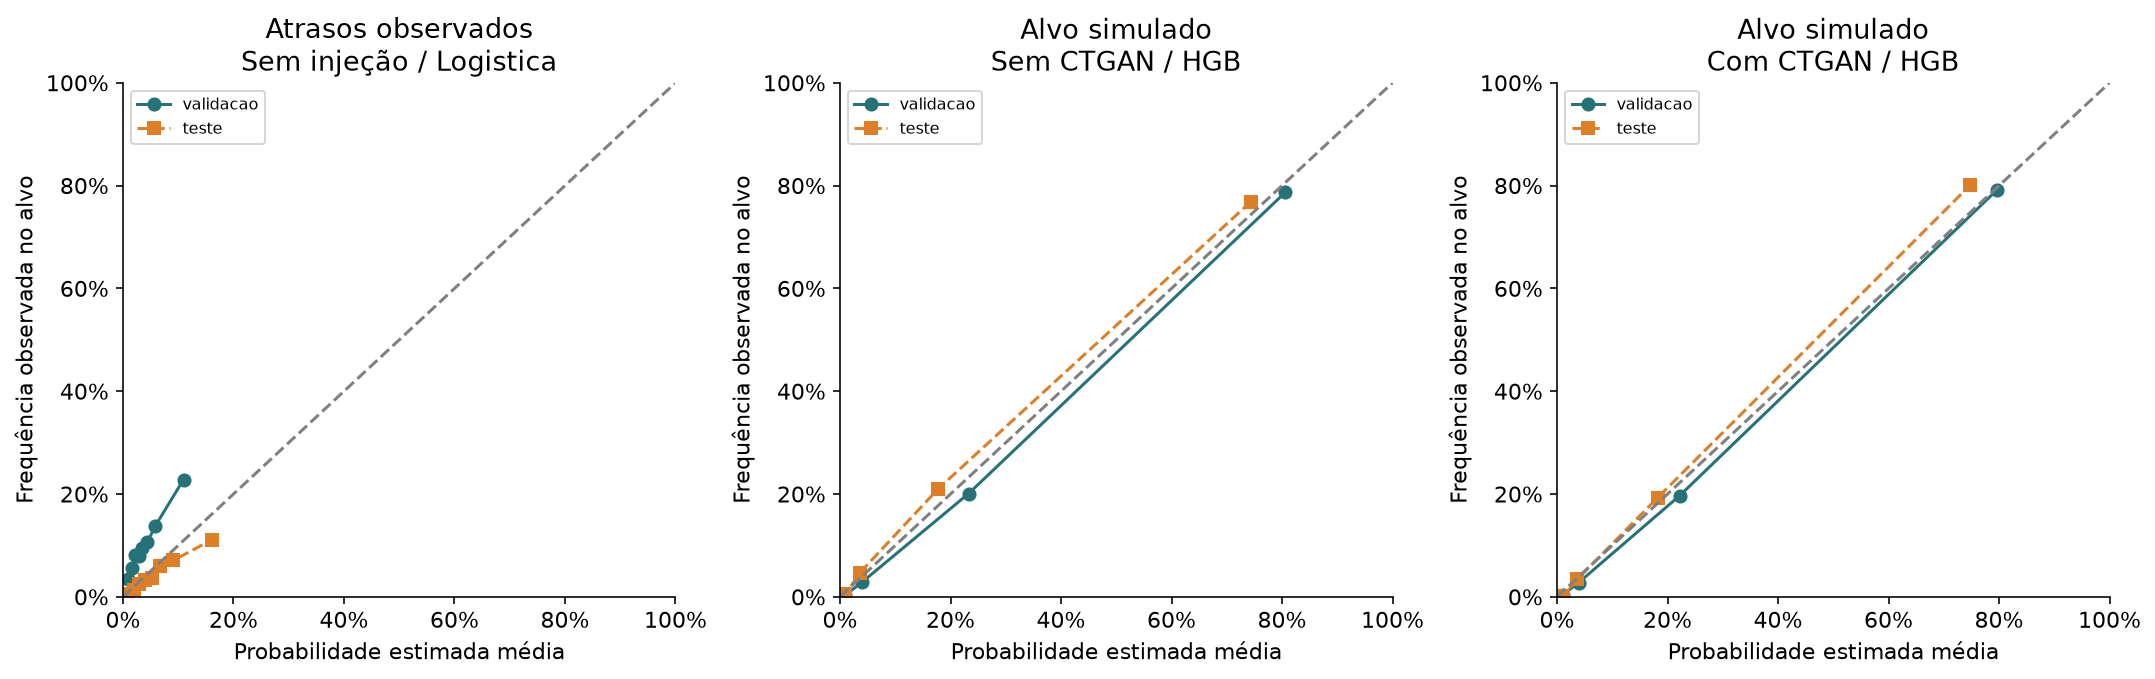

In [9]:
display(Image(filename=str(PASTA / "06_confusao.png")))
display(Image(filename=str(PASTA / "05_calibracao.png")))

## 8. Recarregar e verificar a inferência

Aqui não treinamos de novo. Carregamos os pipelines selecionados, prevemos todos
os pedidos de teste e verificamos os scores contra o CSV salvo. Recalculamos também
as métricas publicadas. Usamos somente os arquivos locais deste experimento.

In [10]:
teste = base.loc[base.particao.eq("teste")]
with threadpool_limits(limits=4):
    for escolha in eleitos.itertuples():
        salvo = joblib.load(PASTA / f"modelo_{escolha.experimento}_{escolha.modelo}.joblib")
        scores = salvo["pipeline"].predict_proba(teste[salvo["colunas"]])[:, 1]
        referencia = previsoes.loc[previsoes.experimento.eq(escolha.experimento)
            & previsoes.modelo.eq(escolha.modelo) & previsoes.particao.eq("teste")]
        referencia = referencia.set_index("order_id").loc[teste.order_id]
        np.testing.assert_allclose(scores, referencia.score, rtol=1e-6, atol=1e-7)
        medido = calcular_metricas(referencia.real, referencia.score, salvo["limiar"])
        linha = resumo.loc[resumo.experimento.eq(escolha.experimento)].iloc[0]
        for metrica in ["f1", "precision", "recall", "AP", "accuracy", "tn", "fp", "fn", "tp"]:
            np.testing.assert_allclose(medido[metrica], linha[metrica], rtol=1e-10, atol=1e-10)
        print(escolha.experimento, ": scores e métricas reproduzidos em", len(teste), "pedidos.")

observado_sem_injecao : scores e métricas reproduzidos em 25120 pedidos.


simulado_sem_ctgan : scores e métricas reproduzidos em 25120 pedidos.


simulado_com_ctgan : scores e métricas reproduzidos em 25120 pedidos.


## 9. Código das figuras e conclusão verificável

As figuras são produzidas por `criar_graficos` em `src/simulacao_logistica/avaliacao.py`.
Esse arquivo contém o código editável de eixos, curvas, matrizes e distribuições.
A célula abaixo permite reconstruí-las a partir dos resultados, sem treinar modelos.
Não escolha novos parâmetros pelo resultado do teste.

In [11]:
REGERAR_FIGURAS = False
if REGERAR_FIGURAS:
    from src.simulacao_logistica.avaliacao import criar_graficos
    criar_graficos(base, sinteticos, resultados, previsoes, PASTA)

comparacao = resultados.loc[resultados.particao.eq("teste")
    & resultados.populacao.eq("atributos_olist")
    & resultados.experimento.str.startswith("simulado")].pivot(index="modelo", columns="experimento", values="f1")
if {"simulado_com_ctgan", "simulado_sem_ctgan"}.issubset(comparacao.columns):
    comparacao["delta_F1_pontos_percentuais"] = 100 * (comparacao.simulado_com_ctgan - comparacao.simulado_sem_ctgan)
    display(comparacao.round(4))
print("Conclusão limitada ao cenário e à semente executados. Não é evidência de ganho no atraso observado.")

experimento,simulado_com_ctgan,simulado_sem_ctgan,delta_F1_pontos_percentuais
modelo,,,
Dummy,0.0000,0.0000,0.0000
HGB,0.7857,0.7535,3.2152
Logistica,0.7116,0.7136,-0.1951


Conclusão limitada ao cenário e à semente executados. Não é evidência de ganho no atraso observado.


## Limitações para o artigo

- O alvo simulado foi construído a partir de hipóteses conhecidas; ele não substitui
  o histórico real. A intensidade configurada influencia quão fácil é aprendê-lo.
- Os dados Olist são antigos, limitados à coorte elegível e a um vendedor por pedido.
- A distância geodésica não representa a rota efetiva; sintéticos não têm endereço
  de origem, e seus pagamentos assumem ausência de descontos.
- Notas de clientes são proxies da qualidade do vendedor. Notas de transportadoras
  são fictícias, com instantes de disponibilidade também simulados.
- Uma semente, sem intervalo de confiança, não comprova ganho estável. O teste já
  foi consultado em outras etapas e os dados sintéticos não são evidência de produção.
- Validação/teste sintéticos opcionais são diagnósticos derivados do mesmo gerador.

Referências: [proposta compartilhada](https://chatgpt.com/s/cx_6af5e63747a48191915d29e4c1cdad3c),
[CTGAN oficial](https://github.com/sdv-dev/CTGAN),
[vazamento de dados — Scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html).